<a href="https://colab.research.google.com/github/NashieliVB/An-lisis-ConnectaTel/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
 # importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head(5)# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head()# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print("Cantidad de valores nulos", users.isna().sum())
print("Proporción de valores nulos", users.isna().mean())

Cantidad de valores nulos user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de valores nulos user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print("Cantidad de valores nulos", usage.isna().sum())
print("Proporción de valores nulos", usage.isna().mean())

Cantidad de valores nulos id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de valores nulos id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
*¿Qué columnas tienen valores faltantes y en qué proporción?*

- del dataset users: **churn_date** presenta más de 88.350% y **city** tiene 11.725% en proporción. El resto de las columnas esta en 0% de proporción.
  
- del dataset usage: **duration** y **lenght** tiene 55.19% y 44.74% de proporción respectivamente.


*Indica qué harías: ¿imputar, eliminar, ignorar?*
- en **churn_date** se puede eliminar.
- en **city** se imputan.
- en **duration** y **lengh** se dejan como nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` en general los datos se observan normales, pero el promedio es igual al Q2.
- La columna `age` que el minimo es -999, lo que representa un outlier.

In [ ]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` el mínimo es un dato que representa un outlier y `user_id`los datos se ven normales.
- Las columnas `duration` y en `lenght`tienen maximo muy alejado del resto de los datos, especialmente en `lenght`.

In [ ]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']].describe()
print(columnas_user)


          city    plan
count     3435    4000
unique       6       2
top     Bogotá  Basico
freq       808    2595


- La columna `city` tiene un conteo de 3531 datos, la ciudad que aparece con mayor frecuencia de 808 es Bogotá.
- La columna `plan` tiene un conteo de 4000 datos, el plan que aparece más es el Basico con 2595 apariciones.

In [ ]:
# explorar columna categórica de usage
usage['type'].describe()


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` tiene un conteo de 40000 datos, el tipo de actividad realizada por lo usuarios con mayor frecuencia es text con 22092 veces.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  en age esta el valor de -999.
- ¿Qué acción tomarías? haria una winsorización.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].describe()

count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

En `reg_date` la última fecha fue muy reciente y es la de mayor frecuencia.

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].describe()

count                             39950
unique                            39950
top       2024-06-16 13:26:59.770494262
freq                                  1
first               2024-01-01 00:00:00
last                2024-06-30 00:00:00
Name: date, dtype: object

En `date`, los registros son del año 2024.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? existen años anteriores al 2024 y posteriores, por lo que se deben segmentar los datos y solo considerar el año 2024 que es el año objetivo de análisis.
- ¿Qué harías con ellas?con los datos anteriores o posteriores se aplica una winsorización.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
users['age'] = users['age'].replace(-999,np.nan)
age_mediana = users['age'].median()
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?",pd.NA)

# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date']<"2024-01-01",'reg_date'] = pd.NaT
users.loc[users['reg_date']>"2024-12-31",'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].describe()

count                              1330
unique                             1330
top       2024-08-11 23:36:14.043510880
freq                                  1
first               2024-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Ambos casos son MAR, pues dependen de 'type', ya que si son mensajes `call` es 0 ya que los mensajes no tienen duración; y pasa exactamento lo contrario en `length`,cuando son llamadas `text`es 0 ya que no hay texto en una llamada.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
cant_llamadas = usage [usage["type"] == "call"].groupby("user_id")["duration"].count().reset_index()
cant_mensajes = usage [usage["type"] == "text"].groupby("user_id")["length"].count().reset_index()
cant_minutos_llamada = usage [usage["type"] == "call"].groupby("user_id")["duration"].sum().reset_index()

# observar resultado
display(cant_llamadas.head(3))
display(cant_mensajes.head(3))
display(cant_minutos_llamada.head(3))


,user_id,duration
0,10000,3
1,10001,10
2,10002,2


,user_id,length
0,10000,7
1,10001,5
2,10002,5


,user_id,duration
0,10000,23.70
1,10001,33.18
2,10002,10.74


In [ ]:
# Renombrar columnas
cant_llamadas = cant_llamadas.rename(columns = {"duration":"cant_llamadas"})
cant_mensajes = cant_mensajes.rename(columns = {"length":"cant_mensajes"})
cant_minutos_llamada = cant_minutos_llamada.rename(columns={"duration":"cant_minutos_llamada"})

# observar resultado
display(cant_llamadas.head(3))
display(cant_mensajes.head(3))
display(cant_minutos_llamada.head(3))

,user_id,cant_llamadas
0,10000,3
1,10001,10
2,10002,2


,user_id,cant_mensajes
0,10000,7
1,10001,5
2,10002,5


,user_id,cant_minutos_llamada
0,10000,23.70
1,10001,33.18
2,10002,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile0 = cant_llamadas.merge(cant_mensajes, on= "user_id")
user_profile = user_profile0.merge(cant_minutos_llamada, on= "user_id")
user_profile.head(5)

,user_id,cant_llamadas,cant_mensajes,cant_minutos_llamada
0,10000,3,7,23.70
1,10001,10,5,33.18
2,10002,2,5,10.74
3,10003,3,11,8.99
4,10004,3,4,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,cant_llamadas,cant_mensajes,cant_minutos_llamada
count,3940.000000,3940.000000,3940.000000,3940.000000
mean,12002.671574,4.518020,5.550508,23.006325
std,1155.161718,2.102581,2.334165,16.370103
min,10000.000000,1.000000,1.000000,0.020000
25%,11001.750000,3.000000,4.000000,11.337500
50%,12005.500000,4.000000,5.000000,19.835000
75%,13001.500000,6.000000,7.000000,31.292500
max,13999.000000,15.000000,17.000000,153.060000


In [ ]:
# Distribución porcentual del tipo de plan
users["plan"].value_counts()

Basico     2595
Premium    1405
Name: plan, dtype: int64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

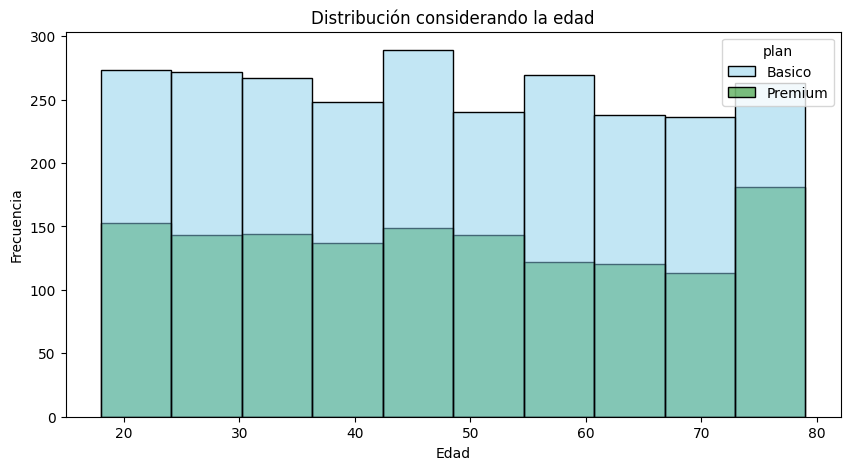

In [ ]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(10,5))
sbn.histplot(data=users, x='age', bins=10, hue ='plan', palette=['skyblue','green'])
plt.title("Distribución considerando la edad")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

💡Insights:
- Distribución de la edad es practicamente la misma considerando la frecuencia. La mayor cantidad de usuarios entan entre los 40 y 50 años, y utilizan de manera proporcional el plan básico y premium. El plan premium es mayormente utilizado por usuarios  entre los 70 y 80 años.  

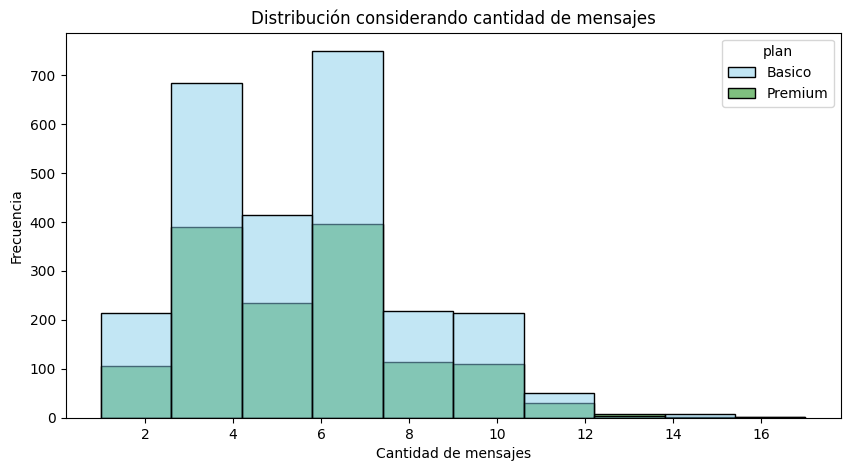

In [ ]:
# Histograma para visualizar la cant_mensajes
user_histograma= user_profile.merge(users, on= "user_id")

plt.figure(figsize=(10,5))
sbn.histplot(data=user_histograma, x='cant_mensajes', bins=10, hue ='plan', palette=['skyblue','green'])
plt.title("Distribución considerando cantidad de mensajes")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Frecuencia")
plt.show()

💡Insights:
- La distribución de cantidad de mensajes presenta un sesgo hacia la izquierda, con un comportamiento de frecuencia mayor entre 3 a 4 mensajes y 6 a 7 mensjaes. De manera general se observa una proporcion equilibrada entre usuarios de plan básico y premium.

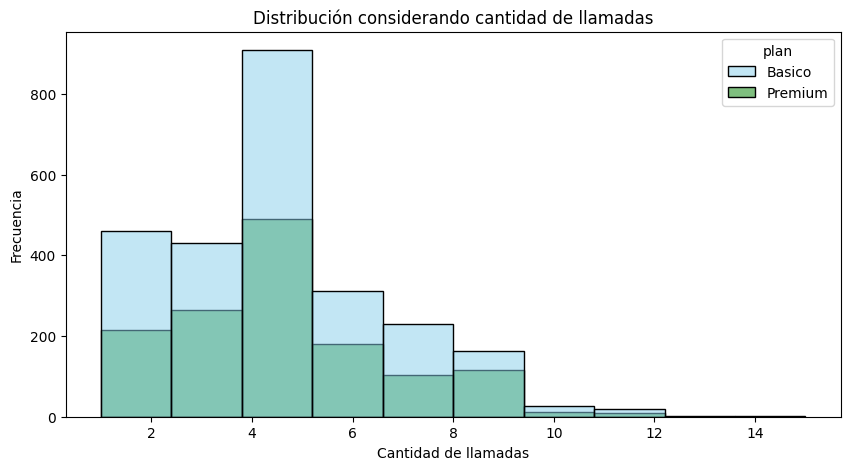

In [ ]:
# Histograma para visualizar la cant_llamadas
user_histograma= user_profile.merge(users, on= "user_id")

plt.figure(figsize=(10,5))
sbn.histplot(data=user_histograma, x='cant_llamadas', bins=10, hue ='plan', palette=['skyblue','green'])
plt.title("Distribución considerando cantidad de llamadas")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Frecuencia")
plt.show()

💡Insights:
- Distribución con sesgo a la izquierda, la mayor frecuencia es en 4 a 5 llamadas. Con una proporcion equitativa en el uso del plan básico y premium, sin embargo, fueron más los usuarios de plan premium hicieron una cantidad de llamadas de 8 a 9.

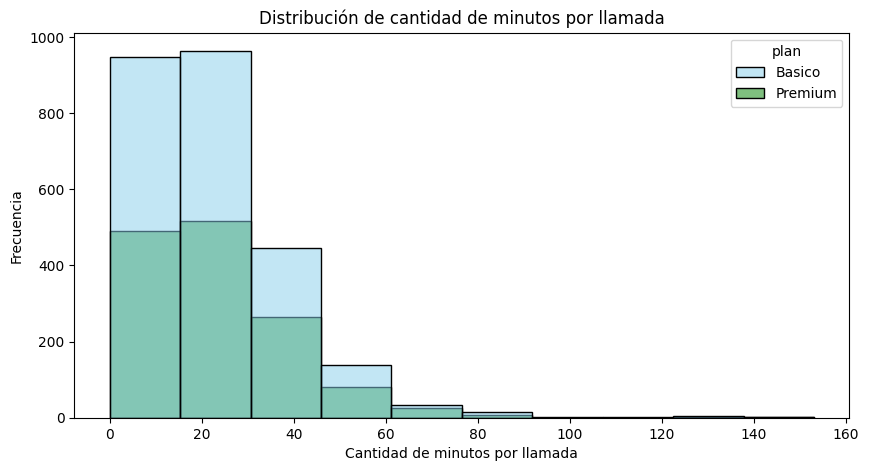

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
user_histograma= user_profile.merge(users, on= "user_id")

plt.figure(figsize=(10,5))
sbn.histplot(data=user_histograma, x='cant_minutos_llamada', bins=10, hue ='plan', palette=['skyblue','green'])
plt.title("Distribución de cantidad de minutos por llamada")
plt.xlabel("Cantidad de minutos por llamada")
plt.ylabel("Frecuencia")
plt.show()

💡Insights:
- La distribución del histograma de cantidad de minutos por llamada tiene un sesgo muy marcado a la izquierda. La mayor cantidad de minutos por llamada estan entre 0 hasta 30, hay una caida notable en la frecuencia en la cantidad de minutos por llamada de 30 a 40. La proporción de usuarios en la cantidad de minutos por llamada de 0 a 45 se observa equitativa entre ambos planes, sin embargo, es notable que los usuarios de plan premium son los que duran más minutos por llamada.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

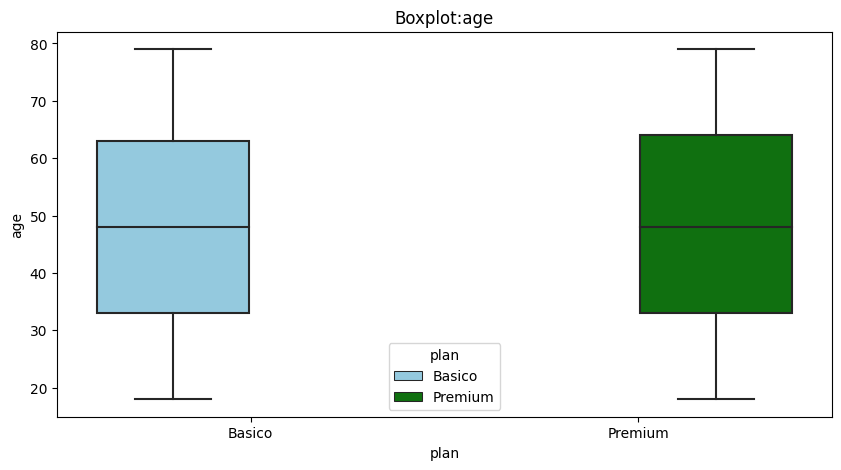

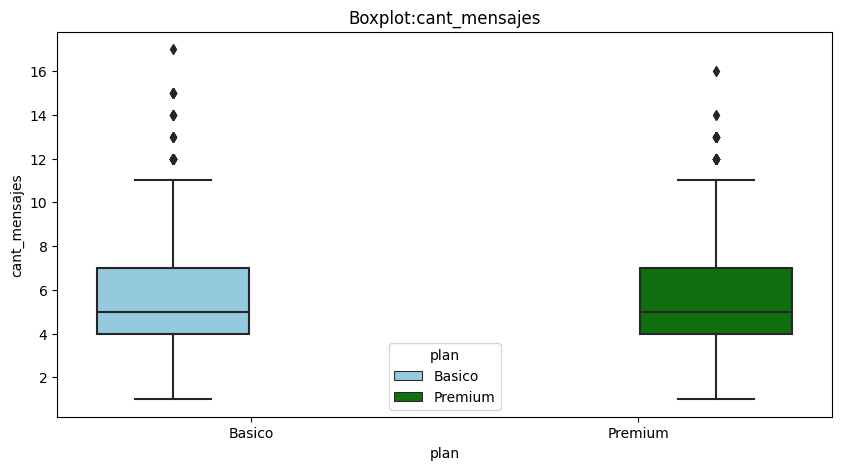

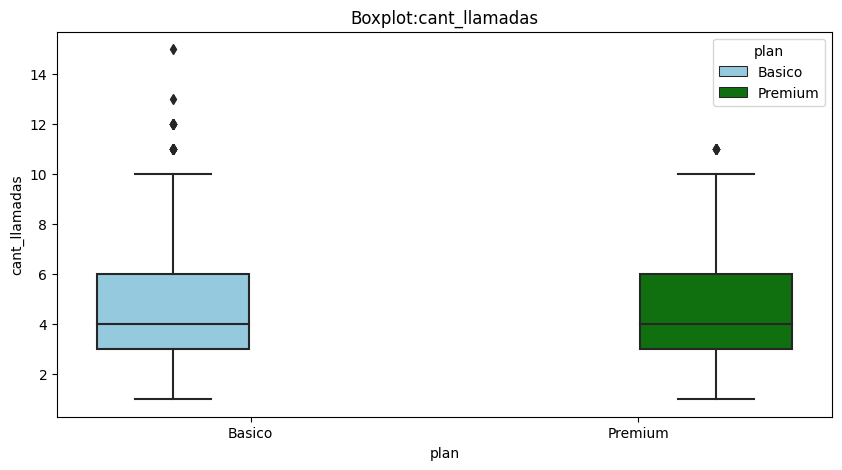

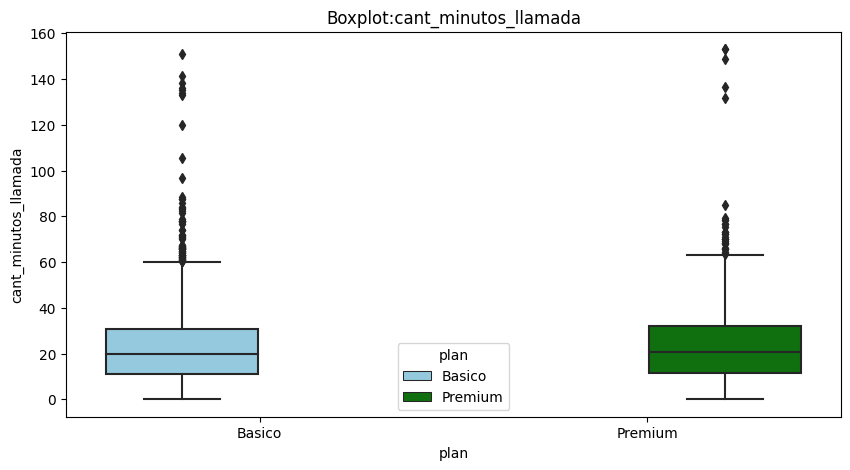

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(10,5))
    sns.boxplot(data=user_histograma, x='plan', y=col, hue='plan',palette=['skyblue','green'])
    plt.title(f'Boxplot:{col}')
    plt.show()


💡Insights:
- Age: no presenta outliers
- cant_mensajes: hay 5 y 4 outliers en el plan basico y premium, respectivamente.
- cant_llamadas: en plan básico hay 4 outliers y en premium solo 1 outlier
- cant_minutos_llamada: se observan outliers en ambos tipos de plan, pero sobre todo en el basico.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1=user_histograma[col].quantile(0.25)
    Q3=user_histograma[col].quantile(0.75)
    IQR=Q3-Q1
    limite_inferior=Q1-1.5*IQR
    limite_superior=Q3+1.5*IQR
    print(f'{col}: limite inferior = {limite_inferior}, limite superior = {limite_superior}')




cant_mensajes: limite inferior = -0.5, limite superior = 11.5
cant_llamadas: limite inferior = -1.5, limite superior = 10.5
cant_minutos_llamada: limite inferior = -18.595, limite superior = 61.224999999999994


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3940.000000,3940.000000,3940.000000
mean,5.550508,4.518020,23.006325
std,2.334165,2.102581,16.370103
min,1.000000,1.000000,0.020000
25%,4.000000,3.000000,11.337500
50%,5.000000,4.000000,19.835000
75%,7.000000,6.000000,31.292500
max,17.000000,15.000000,153.060000


💡Insights:
- cant_mensajes: mantener, porqué? max es 17 y no esta tan alejado de Q3
- cant_llamadas: mantener, porqué? max es 15 y no esta tan alejado de Q3
- cant_minutos_llamada: no mantener outliers, porqué? max de 153 si es muy diferente de Q3, por lo que puede modificar el promedio y la desviación estandar.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso

def grupo_uso(row):
    if row['cant_llamadas']<5 and row['cant_mensajes']<5:
        return 'Bajo uso'
    elif row['cant_llamadas']<10 and row['cant_mensajes']<10:
        return 'Uso medio'
    else:
        return 'Alto Uso'

user_profile['grupo_uso'] = user_profile.apply(grupo_uso,axis=1)


In [ ]:
# verificar cambios
user_profile.head()

,user_id,cant_llamadas,cant_mensajes,cant_minutos_llamada,grupo_uso
0,10000,3,7,23.70,Uso medio
1,10001,10,5,33.18,Alto Uso
2,10002,2,5,10.74,Uso medio
3,10003,3,11,8.99,Alto Uso
4,10004,3,4,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
#verificar columnas de user_profile
user_profile.columns
users.columns

Index(['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan',
       'churn_date'],
      dtype='object')

In [ ]:
#agregar age a user_profile
user_profile = users.merge(user_profile, on='user_id')

user_profile.columns

Index(['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan',
       'churn_date', 'cant_llamadas', 'cant_mensajes', 'cant_minutos_llamada',
       'grupo_uso'],
      dtype='object')

In [ ]:
# Crear columna grupo_edad
def grupo_edad(row):
    if row['age']<30 :
        return 'Joven'
    elif row['age']<60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(grupo_edad,axis=1)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_llamadas,cant_mensajes,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,NaT,Basico,NaN,3,7,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,NaT,Basico,NaN,10,5,33.18,Alto Uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,NaT,Basico,NaN,2,5,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,NaT,Premium,NaN,3,11,8.99,Alto Uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,NaT,Basico,NaN,3,4,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

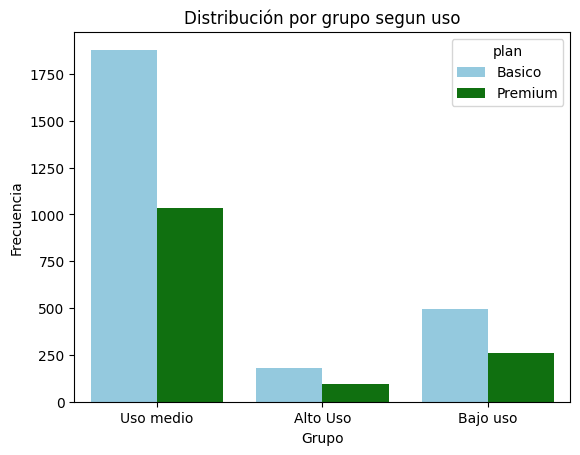

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data= user_profile, x='grupo_uso', hue='plan', palette=['skyblue','green'])
plt.title("Distribución por grupo segun uso")
plt.xlabel("Grupo")
plt.ylabel("Frecuencia")
plt.show()

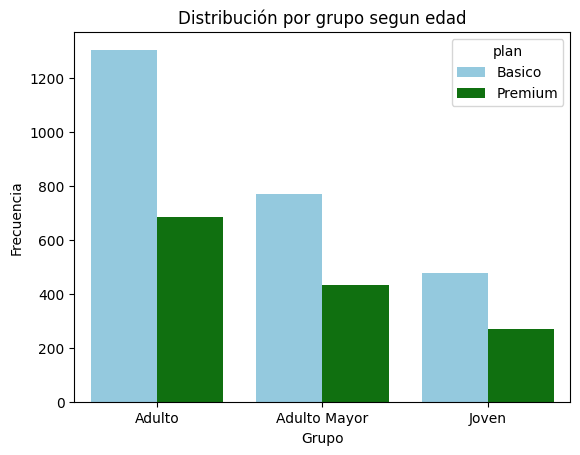

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data= user_profile, x='grupo_edad', hue='plan', palette=['skyblue','green'])
plt.title("Distribución por grupo segun edad")
plt.xlabel("Grupo")
plt.ylabel("Frecuencia")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

*Sobre los valores nulos*
- del dataset users: **churn_date** presenta más de 88.350% y **city** tiene 11.725% en proporción. El resto de las columnas esta en 0% de proporción.
  
- del dataset usage: **duration** y **lenght** tiene 55.19% y 44.74% de proporción respectivamente.

*Sobre valores invalidos*
- La columna age del dataset users tenia el minimo en -999, lo que representa un outlier.
- Del dataset usage: en la columna id el mínimo era un dato que representa un outlier. En las columnas duration y en lenght, el maximo estaba muy alejado del resto de los datos, especialmente en lenght.

- Se observaron patrones de uso extermo sobresalientes en la cantidad de minutos por llamada del plan básico.

🔍 **Segmentos por Edad**
- Los segmentos de acuerdo a la edad son: adultos mayores edad mayor a 60 años, adultos son menores a 60 años, y jovenes menores a 30 años.  
- Son mayor cantidad de usuarios los adultos mayores, seguido de adultos y lo menos son jovenes.
- En los tres segmentos de acuerdo a la edad, la frecuencia de uso es siempre mayor en el plan básico.  


📊 **Segmentos por Nivel de Uso**
- Para segmentar se considero la cantidad de llamadas y mensajes.
- Se segmento en tres grupos de acuerdo al uso: grupo alto con mas de 10 llamadas y mensajes, grupo medio con menos de 10 llamadas y mensajes, y para el grupo bajo con menos de 5 llamadas y mensajes.
- Son muy pocos los usuarios que presentan un uso alto, y mayormente los usuarios tienen un uso medio.
- En los tres segmentos se puede observar que la mayoria de los usuarios son de plan basico. Sin embargo, la diferencia entre la cantidad de usuarios de plan básico y plan premium en el segmento de uso alto es muy poca.


➡️ Esto sugiere que el grupo más valioso para ConnectaTel son los adultos menores de 60 años de plan básico, pues ahi estan la mayor cantidad de usuarios. Además su uso es medio.


💡 **Recomendaciones**
- Crear un plan intermedio entre el básico y premium para incentivar a los usuarios a migrar a un plan mejor, de esa forma se puede disminuir la diferencia entre la cantidad de usuarios adultos con plan básico y adultos de plan premium, que son el mercado más grande.
- Crear además una estrategia para atraer a más usuarios jovenes.  


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`